In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

from diaphanous.arr2 import run_r
from diaphanous.color import Palette
import diaphanous.de as de

import altair as alt
import great_tables as gt
from IPython.display import display, HTML, SVG
import matplotlib.pyplot as plt
import polars as pl

In [2]:
rates = de.combine_offenders_and_outcomes(
    de.de_age_distribution().collect(),
    de.ingest_outcomes(),
).select(
    pl.col("data_year", "age_group", "outcome", "count")
).group_by(
    "data_year", "age_group", "outcome",
    maintain_order=True
).agg(
    pl.col("count").sum()
).with_columns(
    pl.col("outcome").replace_strict({
        "No Sanction": "ignored",
        "Adjudication": "adjudicated",
        "Conviction": "convicted",
    })
).pivot(
    on="outcome",
    index=["data_year", "age_group"],
    values="count",
).filter(
    pl.col("age_group").ne("Child").and_(pl.col("data_year").ne(2025)),
).with_columns(
    pl.col("adjudicated").add(pl.col("convicted")).alias("prosecuted"),
    pl.col("ignored").add(pl.col("adjudicated")).add(pl.col("convicted")).alias("offended"),
).with_columns(
    pl.col("prosecuted").truediv("offended").alias("Prosecution"),
    pl.col("convicted").truediv("prosecuted").alias("Conviction"),
).unpivot(
    on=["Prosecution", "Conviction"],
    index=["data_year", "age_group"],
    variable_name="outcome",
    value_name="rate"
).select(
    pl.col("data_year"),
    pl.format("{} Rate for {}s", pl.col("outcome"), pl.col("age_group")),
    pl.col("rate"),
)

rates

data_year,outcome,rate
i16,str,f64
2015,"""Prosecution Rate for Juveniles""",0.110345
2015,"""Prosecution Rate for Adults""",0.400748
2016,"""Prosecution Rate for Juveniles""",0.142509
2016,"""Prosecution Rate for Adults""",0.448892
2017,"""Prosecution Rate for Juveniles""",0.078818
…,…,…
2022,"""Conviction Rate for Adults""",0.880757
2023,"""Conviction Rate for Juveniles""",0.495633
2023,"""Conviction Rate for Adults""",0.855746


In [3]:
fig = alt.Chart(rates).mark_line().encode(
    alt.X("data_year:O").title(None).axis(labelAngle=-45),
    alt.Y("rate:Q").title(None),
    alt.Color("outcome:N").title(None).scale(
        domain=[
            "Conviction Rate for Adults",
            "Conviction Rate for Juveniles",
            "Prosecution Rate for Adults",
            "Prosecution Rate for Juveniles",
        ],
        range=[
            Palette.PURPLE,
            Palette.GREEN,
            Palette.PINK,
            Palette.CYAN,
        ],
    ).legend(
        orient="none",
        legendX=10,
        legendY=46,
    ),
).properties(
    width=400,
).configure_axis(
    labelFontSize=14,
).configure_legend(
    labelFontSize=14,
    symbolStrokeWidth=4,
    labelLimit=200,
)

fig

alt.Chart(...)

In [4]:
reports = pl.read_csv("../data/ocse-reports-per-year.csv").join(
    pl.read_csv("../data/populations-simple.csv").select(
        pl.col("year"),
        pl.col("population").alias("people"),
    ),
    on="year",
    how="left",
).join(
    pl.read_csv("../data/internet-users-un.csv"),
    on="year",
    how="left",
).join(
    pl.read_csv("../data/social-accounts.csv").select(
        pl.col("year"),
        pl.col("million_accounts").mul(1_000_000).alias("social_accounts"),
    ),
    on="year",
    how="left",
).select(
    pl.col("year", "reports", "people"),
    pl.col("internet_users_pct").mul(
        pl.col("people")
    ).truediv(100).alias("internet_users"),
    pl.col("social_accounts"),
    pl.col("reports").mul(1_000).truediv(
        pl.col("social_accounts")
    ).alias("reports_per_social"),
)

(
    gt.GT(reports)
    .fmt_number(columns="reports_per_social", decimals=3)
    .fmt_number(columns=["reports", "people", "internet_users", "social_accounts"])
    .sub_missing(missing_text="")
)

year,reports,people,internet_users,social_accounts,reports_per_social
2025,"21,351,493.00","8,231,613,070.00","6,058,467,219.52","5,725,000,000.00",3.730
2024,"20,512,803.00","8,161,972,572.50","5,517,493,459.01","5,037,000,000.00",4.072
2023,"36,210,368.00","8,091,734,930.00","5,291,994,644.22","4,770,000,000.00",7.591
2022,"32,059,029.00","8,021,407,192.00","5,109,636,381.30","4,632,000,000.00",6.921
2021,"29,397,681.00","7,954,448,391.50","4,907,894,657.56","4,214,000,000.00",6.976
2020,"21,751,085.00","7,887,001,292.00","4,621,782,757.11","3,726,000,000.00",5.838
2019,"16,987,361.00","7,811,293,698.50","4,132,174,366.51","3,478,000,000.00",4.884
2018,"18,462,422.00","7,729,902,780.50","3,749,002,848.54","3,212,000,000.00",5.748
2017,"10,214,753.00","7,645,617,954.00","3,455,819,315.21","2,804,000,000.00",3.643
2016,"8,297,923.00","7,558,554,525.50","3,235,061,336.91","2,320,000,000.00",3.577


In [5]:
text_sections, data_sections = run_r(
    reports.filter(pl.col("year").is_between(2014, 2023)), """
library(tidyverse)
data <- read.csv(text = "{CSV_DATA}")

# ---------------------------------------------------------------------------------
data.year.em <- lm(log(reports) ~ year, data=data)
emit_text(summary(data.year.em))

# ---------------------------------------------------------------------------------
emit_rule()
data.year.lm <- lm(reports ~ year, data=data)
emit_text(summary(data.year.lm))
data$year_residuals <- rstandard(data.year.lm)
data$year_predicted <- predict(data.year.lm)

svg("../figure/gof-year.svg", width = 8, height = 6)
par(mfrow = c(2, 3))
plot(data.year.lm, which = 1:6)
dev.off()

# ---------------------------------------------------------------------------------
emit_rule()
data.people.lm <- lm(reports ~ people, data=data)
emit_text(summary(data.people.lm))

# ---------------------------------------------------------------------------------
emit_rule()
data.inet.lm <- lm(reports ~ internet_users, data=data)
emit_text(summary(data.inet.lm))

# ---------------------------------------------------------------------------------
emit_rule()
data.social.lm <- lm(reports ~ social_accounts, data=data)
data.social.resid <- rstandard(data.social.lm)
emit_text(summary(data.social.lm))

emit_rule(0)
emit_text(data.social.resid)
data$social_residuals <- data.social.resid
data$social_predicted <- predict(data.social.lm)
emit_data(data[c("year", "social_residuals", "social_predicted", "year_residuals", "year_predicted")])

svg("../figure/gof-social.svg", width = 8, height = 6)
par(mfrow = c(2, 3))
plot(data.social.lm, which = 1:6)
dev.off()

# ---------------------------------------------------------------------------------
emit_rule()
data.year.social.lm <- lm(reports ~ social_accounts + year, data=data)
emit_text(summary(data.year.social.lm))

# ---------------------------------------------------------------------------------
emit_rule()
data.reports.social.lm <- lm(reports_per_social ~ year, data=data)
emit_text(summary(data.reports.social.lm))

emit_data(
    c("Independent Variable", "Dependent Variable", "Intercept", "Slope"),
    c("Year", "Reports", data.year.lm$coefficients[1:2]),
    c("Social Accounts", "Reports", data.social.lm$coefficients[1:2]),
    c("Year", "Reports per Social Accounts", data.reports.social.lm$coefficients[1:2])
)
""")

for t in text_sections:
    print(t)

Call:
lm(formula = log(reports) ~ year, data = data)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.96075 -0.14269  0.07824  0.24818  0.54989 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept) -641.82807  102.69611  -6.250 0.000246 ***
year           0.32607    0.05088   6.409 0.000207 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.4621 on 8 degrees of freedom
Multiple R-squared:  0.837,    Adjusted R-squared:  0.8166 
F-statistic: 41.07 on 1 and 8 DF,  p-value: 0.0002072

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Call:
lm(formula = reports ~ year, data = data)

Residuals:
     Min       1Q   Median       3Q      Max 
-2865792 -1279076   342308   831642  2537505 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept) -7.911e+09  4.030e+08  -19.63 4.72e-08 ***
year         3.928e+06  1.997e+05   19.67 4.64e-08 ***
---
Signif

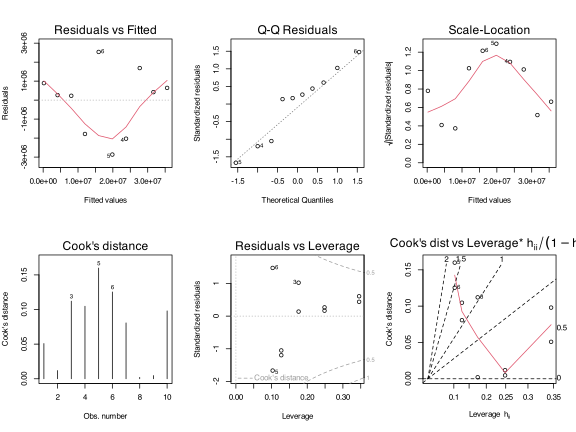

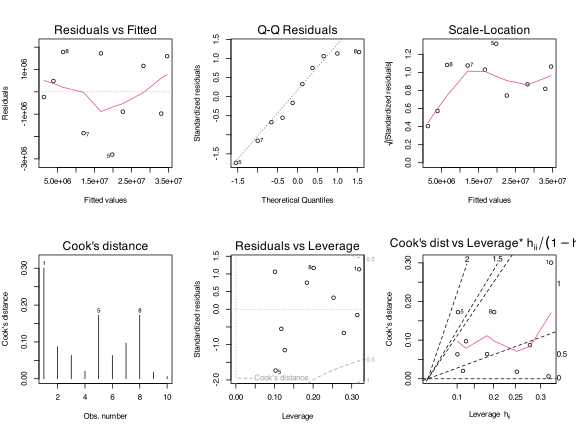

In [6]:
for file in ("gof-year.svg", "gof-social.svg"):
    fig = (Path.cwd() / ".." / "figure" / file).read_text("utf8")
    display(HTML("<hr>"))
    display(SVG(fig))

Call:
lm(formula = log(reports) ~ year, data = data)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.95745 -0.49054  0.04278  0.48085  0.84256 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept) -710.54007   31.73968  -22.39   <2e-16 ***
year           0.35997    0.01579   22.80   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.6037 on 24 degrees of freedom
Multiple R-squared:  0.9559,    Adjusted R-squared:  0.954 
F-statistic: 519.9 on 1 and 24 DF,  p-value: < 2.2e-16

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

***Regression Model with Segmented Relationship(s)***

Call: 
segmented.lm(obj = fit)

Estimated Break-Point(s):
             Est. St.Err
psi1.year 2014.2  0.231

Coefficients of the linear terms:
             Estimate Std. Error t value Pr(>|t|)
(Intercept) -83472673  107129154  -0.779    0.444
year            41710      53404   0.781   

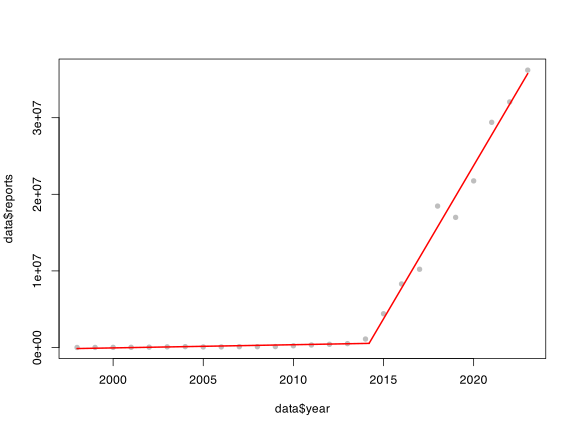

In [7]:
text_sections, _ = run_r(
    reports.filter(pl.col("year").le(2023)), """
library(tidyverse)
library(segmented)
data <- read.csv(text = "{CSV_DATA}")

exp_fit <- lm(log(reports) ~ year, data=data)
emit_text(summary(exp_fit))

emit_rule()
fit <- lm(reports ~ year, data=data)
seg_fit <- segmented(fit)
emit_text(summary(seg_fit))
emit_text(slope(seg_fit))

svg("../figure/exp-v-lm.svg", width = 8, height = 6)
plot(data$year, data$reports, pch = 16, col = "gray")
plot(seg_fit, add = TRUE, col = "red", lwd = 2)
dev.off()

""")

for t in text_sections:
    print(t)

for file in ("exp-v-lm.svg",):
    fig = (Path.cwd() / ".." / "figure" / file).read_text("utf8")
    display(HTML("<hr>"))
    display(SVG(fig))

In [8]:
reports2 = reports.join(
    data_sections[0],
    on="year",
    how="left",
)

reports2

year,reports,people,internet_users,social_accounts,reports_per_social,social_residuals,social_predicted,year_residuals,year_predicted
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
2025,21351493,8.2316e9,6.0585e9,5.7250e9,3.729518,null,null,null,null
2024,20512803,8.1620e9,5.5175e9,5.0370e9,4.072425,null,null,null,null
2023,36210368,8.0917e9,5.2920e9,4.7700e9,7.591272,1.132354,3.4614e7,0.439097,3.5566e7
2022,32059029,8.0214e9,5.1096e9,4.6320e9,6.921207,-0.670105,3.3031e7,0.267885,3.1638e7
2021,29397681,7.9544e9,4.9079e9,4.2140e9,6.976194,0.752296,2.8236e7,1.025233,2.7710e7
…,…,…,…,…,…,…,…,…,…
2002,43078,6.3377e9,null,9.5e7,0.453453,null,null,null,null
2001,24442,6.2549e9,null,4.2e7,0.581952,null,null,null,null
2000,19245,6.1717e9,null,2.5e7,0.7698,null,null,null,null


In [ ]:
base = alt.Chart(reports2.with_columns(
    pl.col("year").cast(pl.String),
    pl.col("reports", "social_predicted", "year_predicted").truediv(1_000_000),
))

upperX = alt.X("year:T").axis(labels=False).title(None)
colors = [Palette.BLUE, Palette.RED, Palette.PINK]

upper = alt.layer(
    base.mark_line(color=Palette.GRAY).encode(
        upperX,
        alt.Y("year_predicted:Q").axis(
            None
        ).title(
            None
        )
    ),
    base.mark_line(color=colors[0]).encode(
        upperX,
        alt.Y("reports:Q").axis(
            orient="right",
            titleColor=colors[0],
            titleFontSize=16,
            titleFontWeight="normal",
            titleFontStyle="italic",
            titleAngle=270,
            titlePadding=25,
            labelColor=colors[0],
            labelFontSize=14,
        ).title(
            "Reports in Millions"
        ),
    ),
    base.mark_line(color=colors[1]).encode(
        upperX,
        alt.Y("reports_per_social:Q").axis(
            titleColor=colors[1],
            titleFontSize=16,
            titleFontWeight="normal",
            titleFontStyle="italic",
            titlePadding=10,
            labelColor=colors[1],
            labelFontSize=14,
        ).title(
            "Reports per 1k Social Accounts"
        ),
    ),
).properties(
    width=500,
).resolve_scale(
    x="shared",
    y="independent",
)

lower = base.mark_bar(size=15, color=colors[2]).encode(
    alt.X("year:T").axis(
        titleFontSize=16,
        titleFontWeight="normal",
        titleFontStyle="italic",
        titlePadding=5,
        labelFontSize=14,
        labelAngle=-45,
    ).title(
        "Year"
    ),
    alt.Y("social_residuals:Q").axis(
        orient="right",
        titleColor=colors[2],
        titleFontSize=16,
        titleFontWeight="normal",
        titleFontStyle="italic",
        titleAngle=270,
        labelColor=colors[2],
        labelFontSize=14,
    ).scale(
        domain=[-2, 2],
    ).title(
        ["Standard", "Residuals"]
    ),
).properties(
    width=500,
    height=100,
)

fig = alt.vconcat(upper, lower, spacing=0).resolve_scale(
    x="shared",
    y="independent",
)

fig

alt.VConcatChart(...)

Figure includes:

- Reports per year in millions (upper right, blue)
- Predicted reports in millions based on linear model relating reports to years (upper right, gray)
- Reports per 1,000 social accounts (upper left, red)
- Standard residuals for linear model relating reports to social accounts

In [ ]:
base = alt.Chart(reports2)
points = base.encode(
    alt.X("social_accounts:Q"),
    alt.Y("reports:Q"),
)

fig2 = alt.layer(
    points.mark_line(),
    # points.mark_text().encode(alt.Text("year:N")),
    points.mark_line(color=Palette.GRAY).encode(alt.Y("social_predicted:Q"))
).properties(
    width=500
)

fig2

alt.LayerChart(...)

In [10]:
ns = [6, 6, 2, 6, 2, 6, 3, 6, 7, 4, 3, 1]
sum(ns)/len(ns)

4.333333333333333